# PCA
Aldo asked me to apply probabilistic PCA (PPCA) to hourly features as a means of dimensionality reduction. Not sure this is actually appropriate, I tried kernel PCA but dataset is way too big for that. 
Wants me to look at: how many components to explain the variance, whether patient groups cluster. Said something about passing data through autoencoders with different numbers of nodes (e.g. 1, 2, 3 etc)

In [1]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import FactorAnalysis, PCA, KernelPCA
from sklearn.preprocessing import StandardScaler

# Sepsis patients only
## predicting mortality

In [2]:
df_path = "/home/jake/Documents/AI_Clinician/choc_data/combined_data/hourly/combined_hourly_features_phoenix_sepsis_prop_0.8.parquet"
df = pd.read_parquet(df_path)
df

,encounter_id,time,airway_type,breath_sequence,control_variable,expiratory_pressure,fio2,mean_airway_pressure,mode_of_ventilation,nitric_oxide,...,temperature,vis,age,mortality,sex,white,black,hispanic,asian,other
0,1165711196,2239-11-13 13:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,36.800,0.0,0.00,0.0,1.0,0,0,0,1,0
1,1165711196,2239-11-13 14:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,36.875,0.0,0.00,0.0,1.0,0,0,0,1,0
2,1165711196,2239-11-13 15:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,36.950,0.0,0.00,0.0,1.0,0,0,0,1,0
3,1165711196,2239-11-13 16:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.025,0.0,0.00,0.0,1.0,0,0,0,1,0
4,1165711196,2239-11-13 17:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.100,0.0,0.00,0.0,1.0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1818558,1189429156,2254-11-02 19:00:00,2.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.150,0.0,232.44,0.0,1.0,1,0,0,0,0
1818559,1189429156,2254-11-02 20:00:00,2.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.100,0.0,232.44,0.0,1.0,1,0,0,0,0
1818560,1189429156,2254-11-02 21:00:00,2.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.100,0.0,232.44,0.0,1.0,1,0,0,0,0
1818561,1189429156,2254-11-02 22:00:00,2.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.100,0.0,232.44,0.0,1.0,1,0,0,0,0


In [3]:
df.columns

Index(['encounter_id', 'time', 'airway_type', 'breath_sequence',
       'control_variable', 'expiratory_pressure', 'fio2',
       'mean_airway_pressure', 'mode_of_ventilation', 'nitric_oxide',
       'oxygen_flow', 'peep', 'pip', 'weight_kg', 'ecls_support_type',
       'on_ecls', 'cisatracurium', 'furosemide', 'hydralazine', 'labetalol',
       'nitroglycerin', 'nitroprusside', 'intake', 'alt', 'calcium',
       'chloride', 'creatinine', 'crp', 'hematocrit', 'hemoglobin',
       'neutrophil_count', 'neutrophil_percent', 'potassium', 'random_glucose',
       'sodium', 'white_blood_cell_count', 'fixed_pupils',
       'pupil_reaction_left_binary', 'pupil_reaction_right_binary',
       'chloral_hydrate', 'chlorothiazide', 'dexamethasone', 'dobutamine_dose',
       'furosemide_med', 'hydrocortisone', 'methylprednisolone', 'metolazone',
       'prednisolone', 'spironolactone', 'cisatracurium_med', 'clonidine_med',
       'dexmedetomidine_infusion', 'dexmedetomidine_med', 'fentanyl_infusion'

### only including physiological variables
### also excluding binary indicators (mostly pupil related) since PCA can overestimate their contributions

In [4]:
cols_to_keep = ['weight_kg', 'alt', 'calcium',
       'chloride', 'creatinine', 'crp', 'hematocrit', 'hemoglobin',
       'neutrophil_count', 'neutrophil_percent', 'potassium', 'random_glucose',
       'sodium', 'white_blood_cell_count',
       'blood_pressure_diastolic', 'blood_pressure_mean',
       'blood_pressure_systolic', 'capillary_refill', 'heart_rate',
       'oxygen_saturation', 'respiratory_rate', 'temperature', 'age',
       'sex', 'white', 'black', 'hispanic', 'asian', 'other']

In [5]:
# get the mortality encounters
mortality_encounters = df[df['mortality'] == 1]['encounter_id'].unique()
len(mortality_encounters)

220

In [6]:
df['mortality'].value_counts()

mortality
0.0    1818343
1.0        220
Name: count, dtype: int64

In [7]:
# make all mortality encounters have mortality = 1
df.loc[df['encounter_id'].isin(mortality_encounters), 'mortality'] = 1
df['mortality'].value_counts()

mortality
0.0    1656993
1.0     161570
Name: count, dtype: int64

In [8]:
# create a new dataframe with only the final 24 rows of each encounter
final_24_df = df.groupby('encounter_id').tail(24)
final_24_df.shape

(57123, 84)

In [9]:
# separate features and labels
X = df[cols_to_keep]
y = df['mortality']

X_final_24 = final_24_df[cols_to_keep]
y_final_24 = final_24_df['mortality']

In [10]:
# fit the scaler to X then transform X and X_final_24
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_final_24_scaled = scaler.transform(X_final_24)

In [11]:

pca = PCA(n_components=None, svd_solver='randomized', random_state=0)  # randomized = faster
pca = pca.fit(X_scaled)
Z = pca.transform(X_scaled)

Z_final_24 = pca.transform(X_final_24_scaled)

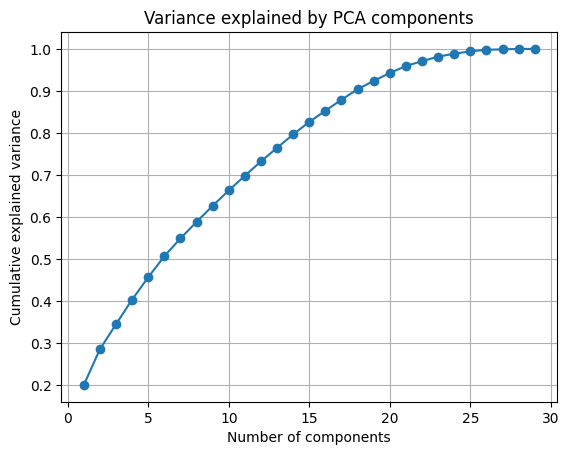

In [12]:
import numpy as np
import matplotlib.pyplot as plt

explained = np.cumsum(pca.explained_variance_ratio_)

plt.plot(np.arange(1, len(explained)+1), explained, marker='o')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.title('Variance explained by PCA components')
plt.grid(True)
plt.show()

In [13]:
df_pca = pd.DataFrame(Z, columns=[f'PC{i+1}' for i in range(Z.shape[1])])
df_pca['mortality'] = y.values 

df_pca_final_24 = pd.DataFrame(Z_final_24, columns=[f'PC{i+1}' for i in range(Z_final_24.shape[1])])
df_pca_final_24['mortality'] = y_final_24.values

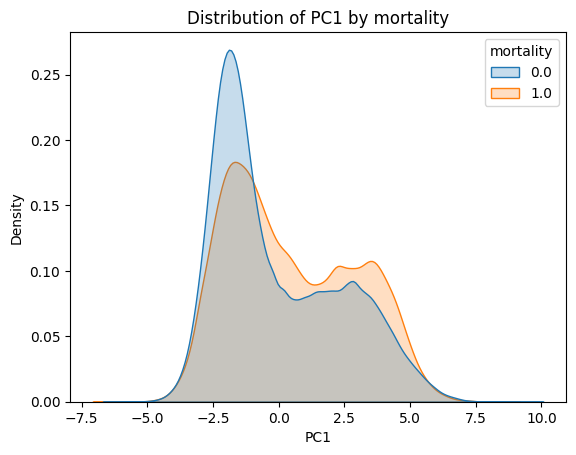

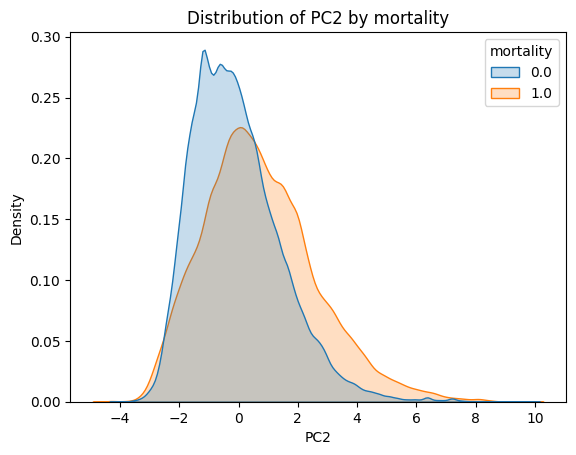

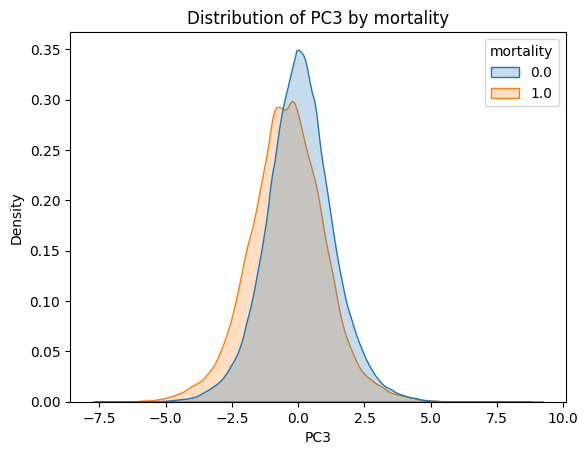

In [14]:
for i in range(3):  # first few components
    sns.kdeplot(data=df_pca, x=f'PC{i+1}', hue='mortality', fill=True, common_norm=False, )
    plt.title(f'Distribution of PC{i+1} by mortality')
    plt.show()

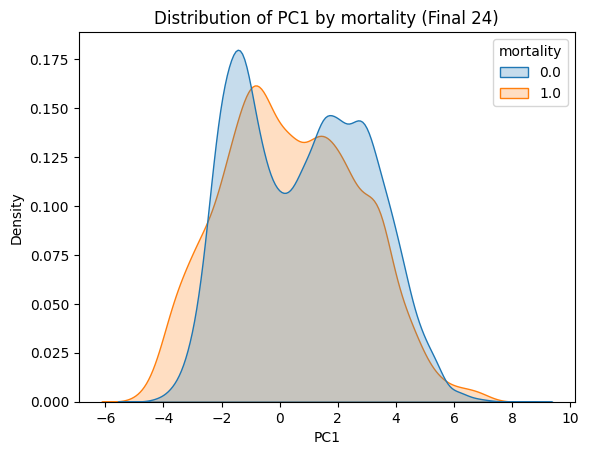

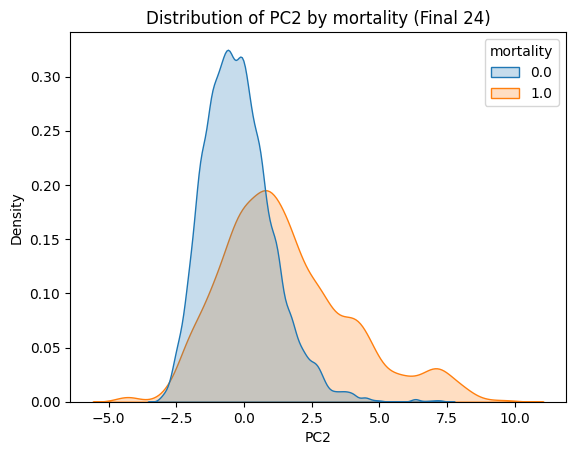

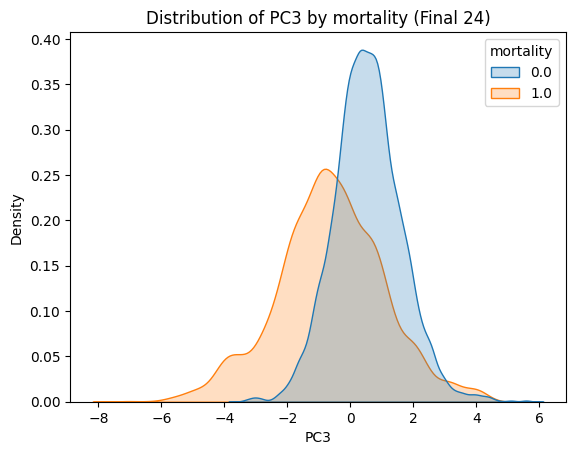

In [15]:

for i in range(3):  # first few components
    sns.kdeplot(data=df_pca_final_24, x=f'PC{i+1}', hue='mortality', fill=True, common_norm=False, )
    plt.title(f'Distribution of PC{i+1} by mortality (Final 24)')
    plt.show()

AUC using all PCA components: 0.758
AUPRC: 0.278


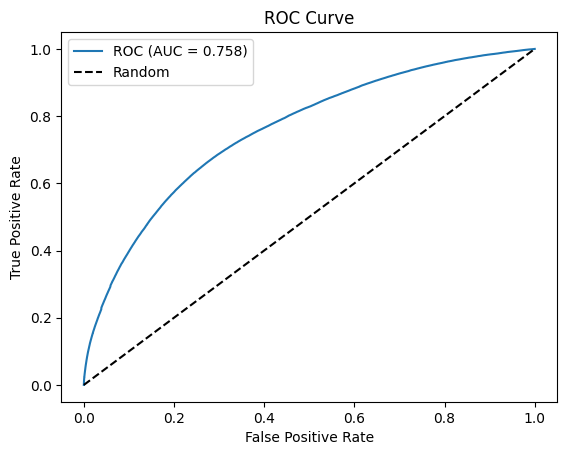

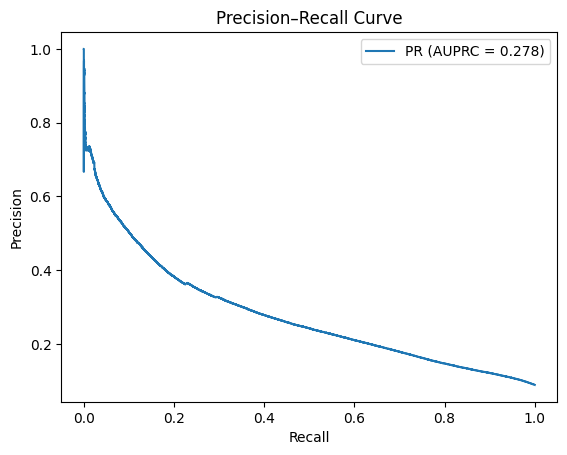

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, RocCurveDisplay, roc_auc_score, average_precision_score, precision_recall_curve, PrecisionRecallDisplay

import matplotlib.pyplot as plt

X_pca = df_pca.drop(columns='mortality').values
y = df_pca['mortality'].values

logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_pca, y)
y_pred = logreg.predict_proba(X_pca)[:, 1]

auc = roc_auc_score(y, y_pred)
print(f"AUC using all PCA components: {auc:.3f}")

auprc = average_precision_score(y, y_pred)
print(f"AUPRC: {auprc:.3f}")

fpr, tpr, _ = roc_curve(y, y_pred)
plt.plot(fpr, tpr, label=f"ROC (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()


precision, recall, _ = precision_recall_curve(y, y_pred)
plt.plot(recall, precision, label=f"PR (AUPRC = {auprc:.3f})")
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision–Recall Curve')
plt.legend()
plt.show()

AUC using all PCA components: 0.937
AUPRC: 0.800


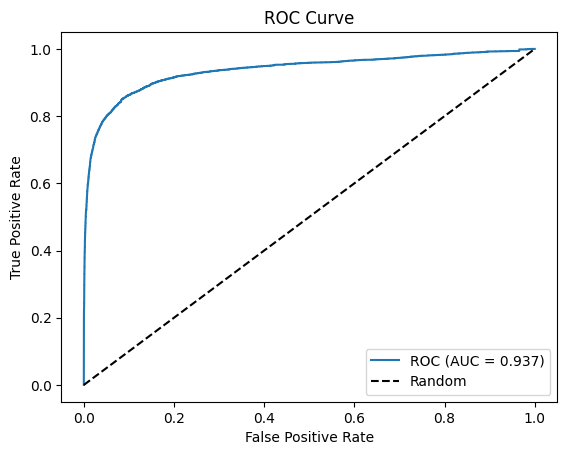

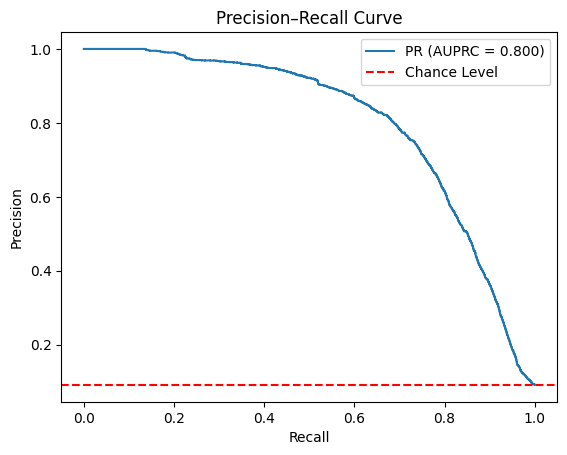

In [17]:
X_final_24_pca = df_pca_final_24.drop(columns='mortality').values
y_final_24 = df_pca_final_24['mortality'].values

logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_final_24_pca, y_final_24)
y_final_24_pred = logreg.predict_proba(X_final_24_pca)[:, 1]

auc = roc_auc_score(y_final_24, y_final_24_pred)
print(f"AUC using all PCA components: {auc:.3f}")

auprc = average_precision_score(y_final_24, y_final_24_pred)
print(f"AUPRC: {auprc:.3f}")

fpr, tpr, _ = roc_curve(y_final_24, y_final_24_pred)
plt.plot(fpr, tpr, label=f"ROC (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()


precision, recall, _ = precision_recall_curve(y_final_24, y_final_24_pred)
plt.plot(recall, precision, label=f"PR (AUPRC = {auprc:.3f})")
# plot the chance level precision
chance_level = y_final_24.sum() / len(y_final_24)
plt.axhline(y=chance_level, color='r', linestyle='--', label='Chance Level')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision–Recall Curve')
plt.legend()
plt.show()

In [18]:
aucs = []
auprcs = []
for i in range(Z_final_24.shape[1]):
    auc = roc_auc_score(y_final_24, Z_final_24[:, i])
    aucs.append(auc)

    auprc = average_precision_score(y_final_24, Z_final_24[:, i])
    auprcs.append(auprc)

    print(f"PC{i+1}: AUC={auc:.3f}, AUPRC={auprc:.3f}")  

PC1: AUC=0.455, AUPRC=0.083
PC2: AUC=0.733, AUPRC=0.364
PC3: AUC=0.274, AUPRC=0.064
PC4: AUC=0.582, AUPRC=0.256
PC5: AUC=0.682, AUPRC=0.384
PC6: AUC=0.384, AUPRC=0.109
PC7: AUC=0.539, AUPRC=0.127
PC8: AUC=0.516, AUPRC=0.129
PC9: AUC=0.605, AUPRC=0.264
PC10: AUC=0.619, AUPRC=0.217
PC11: AUC=0.666, AUPRC=0.299
PC12: AUC=0.448, AUPRC=0.107
PC13: AUC=0.364, AUPRC=0.111
PC14: AUC=0.473, AUPRC=0.112
PC15: AUC=0.701, AUPRC=0.322
PC16: AUC=0.698, AUPRC=0.359
PC17: AUC=0.464, AUPRC=0.155
PC18: AUC=0.482, AUPRC=0.175
PC19: AUC=0.384, AUPRC=0.124
PC20: AUC=0.413, AUPRC=0.091
PC21: AUC=0.383, AUPRC=0.094
PC22: AUC=0.446, AUPRC=0.119
PC23: AUC=0.564, AUPRC=0.242
PC24: AUC=0.417, AUPRC=0.096
PC25: AUC=0.594, AUPRC=0.200
PC26: AUC=0.473, AUPRC=0.088
PC27: AUC=0.487, AUPRC=0.163
PC28: AUC=0.522, AUPRC=0.101
PC29: AUC=0.371, AUPRC=0.120


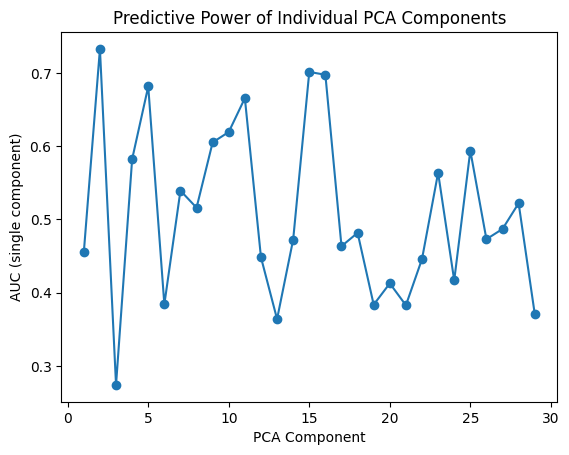

In [19]:
plt.plot(range(1, len(aucs)+1), aucs, marker='o')
plt.xlabel('PCA Component')
plt.ylabel('AUC (single component)')
plt.title('Predictive Power of Individual PCA Components')
plt.show()

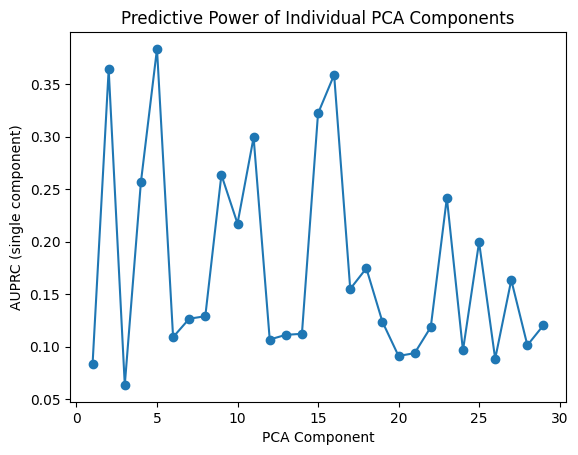

In [20]:
plt.plot(range(1, len(auprcs)+1), auprcs, marker='o')
plt.xlabel('PCA Component')
plt.ylabel('AUPRC (single component)')
plt.title('Predictive Power of Individual PCA Components')
plt.show()

In [21]:
# rank PCs by the auprc scores
sorted_indices = np.argsort(auprcs)[::-1]
top_pcs = []
for i in sorted_indices:
    print(f"PC{i+1}: AUC={aucs[i]:.3f}, AUPRC={auprcs[i]:.3f}")
    top_pcs.append(f"PC{i+1}")

PC5: AUC=0.682, AUPRC=0.384
PC2: AUC=0.733, AUPRC=0.364
PC16: AUC=0.698, AUPRC=0.359
PC15: AUC=0.701, AUPRC=0.322
PC11: AUC=0.666, AUPRC=0.299
PC9: AUC=0.605, AUPRC=0.264
PC4: AUC=0.582, AUPRC=0.256
PC23: AUC=0.564, AUPRC=0.242
PC10: AUC=0.619, AUPRC=0.217
PC25: AUC=0.594, AUPRC=0.200
PC18: AUC=0.482, AUPRC=0.175
PC27: AUC=0.487, AUPRC=0.163
PC17: AUC=0.464, AUPRC=0.155
PC8: AUC=0.516, AUPRC=0.129
PC7: AUC=0.539, AUPRC=0.127
PC19: AUC=0.384, AUPRC=0.124
PC29: AUC=0.371, AUPRC=0.120
PC22: AUC=0.446, AUPRC=0.119
PC14: AUC=0.473, AUPRC=0.112
PC13: AUC=0.364, AUPRC=0.111
PC6: AUC=0.384, AUPRC=0.109
PC12: AUC=0.448, AUPRC=0.107
PC28: AUC=0.522, AUPRC=0.101
PC24: AUC=0.417, AUPRC=0.096
PC21: AUC=0.383, AUPRC=0.094
PC20: AUC=0.413, AUPRC=0.091
PC26: AUC=0.473, AUPRC=0.088
PC1: AUC=0.455, AUPRC=0.083
PC3: AUC=0.274, AUPRC=0.064


In [22]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=[f for f in X_final_24.columns if f not in ['mortality']],
    columns=[f'PC{i+1}' for i in range(pca.n_components_)]
)

# print top 10 features for each of the top 7 predictive components using sorted_indices
for pc in top_pcs:
    print(f"\nTop features for {pc}:")
    print(loadings[pc].sort_values(key=abs, ascending=False).head(10))


Top features for PC5:
chloride                    0.584566
sodium                      0.540601
blood_pressure_mean        -0.274511
blood_pressure_diastolic   -0.271629
blood_pressure_systolic    -0.193726
hemoglobin                 -0.181577
hematocrit                 -0.176763
potassium                  -0.157814
calcium                    -0.150695
creatinine                  0.126895
Name: PC5, dtype: float64

Top features for PC2:
neutrophil_count          0.483538
white_blood_cell_count    0.422464
neutrophil_percent        0.403114
hematocrit                0.369239
hemoglobin                0.360011
creatinine                0.205293
random_glucose            0.184424
oxygen_saturation        -0.178981
potassium                -0.101448
calcium                  -0.098537
Name: PC2, dtype: float64

Top features for PC16:
crp                   0.532136
potassium             0.421197
random_glucose        0.382982
temperature          -0.360148
neutrophil_percent   -0.263395
his

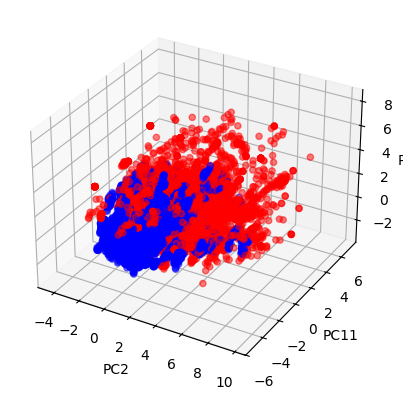

In [23]:
from mpl_toolkits.mplot3d import Axes3D

# Replace these with your actual PC2, PC11, PC16 arrays
x = df_pca_final_24['PC2']
y = df_pca_final_24['PC11']
z = df_pca_final_24['PC16']

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
colors = df_pca_final_24['mortality'].map({0: 'blue', 1: 'red'})

ax.scatter(x, y, z, c=colors, alpha=0.5)

ax.set_xlabel('PC2')
ax.set_ylabel('PC11')
ax.set_zlabel('PC16')
plt.show()

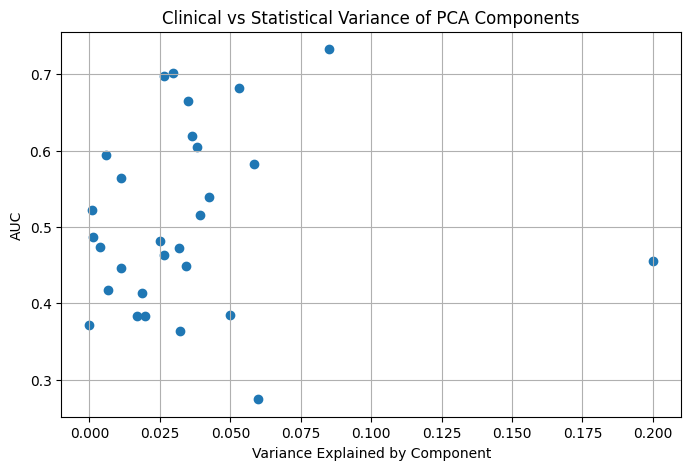

In [24]:
explained = pca.explained_variance_ratio_

plt.figure(figsize=(8,5))
plt.scatter(explained, aucs)
plt.xlabel('Variance Explained by Component')
plt.ylabel('AUC')
plt.title('Clinical vs Statistical Variance of PCA Components')
plt.grid(True)
plt.show()

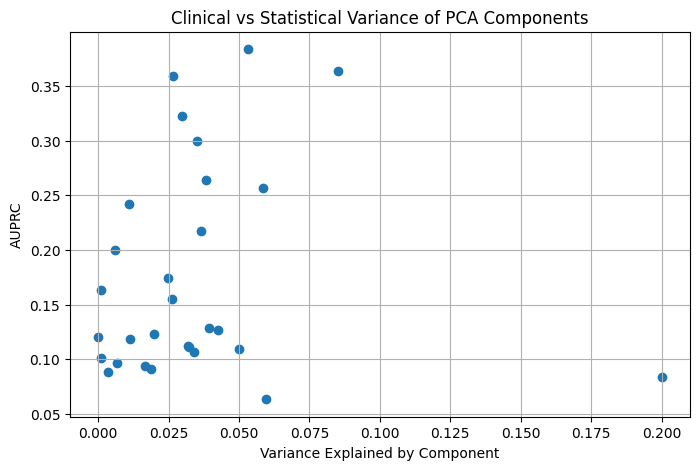

In [25]:
explained = pca.explained_variance_ratio_

plt.figure(figsize=(8,5))
plt.scatter(explained, auprcs)
plt.xlabel('Variance Explained by Component')
plt.ylabel('AUPRC')
plt.title('Clinical vs Statistical Variance of PCA Components')
plt.grid(True)
plt.show()

# Autoencoder as a "non-linear PCA"

In [33]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# Convert to torch tensors
X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
dataset = TensorDataset(X_tensor)
loader = DataLoader(dataset, batch_size=2048, shuffle=True)

# Define the autoencoder architecture
class Autoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim=4):
        super(Autoencoder, self).__init__()
        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)  # Bottleneck
        )
        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, input_dim),
        )

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat, z
    

class VAE(nn.Module):
    def __init__(self, input_dim, latent_dim=2):
        super(VAE, self).__init__()
        # Encoder
        self.fc1 = nn.Linear(input_dim, 64)
        self.fc2_mu = nn.Linear(64, latent_dim)
        self.fc2_logvar = nn.Linear(64, latent_dim)
        # Decoder
        self.fc3 = nn.Linear(latent_dim, 64)
        self.fc4 = nn.Linear(64, input_dim)
        self.relu = nn.ReLU()

    def encode(self, x):
        h = self.relu(self.fc1(x))
        mu = self.fc2_mu(h)
        logvar = self.fc2_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        h = self.relu(self.fc3(z))
        return self.fc4(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decode(z)
        return x_hat, mu, logvar

def vae_loss(x_hat, x, mu, logvar):
    recon_loss = nn.functional.mse_loss(x_hat, x, reduction='sum')
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon_loss + kl_loss




In [ ]:
def train_autoencoder(X_scaled, latent_dim, model_type = "VAE", n_epochs=25, batch_size=2048, lr=1e-3):
        
    # Convert to torch tensors
    X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
    dataset = TensorDataset(X_tensor)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    # create storage for losses which we will plot after
    losses = []

    print(f"\nTraining autoencoder with latent dimension: {latent_dim}")
    # Initialize
    input_dim = X_scaled.shape[1]
    
    if model_type == "VAE":
        model = VAE(input_dim, latent_dim)
        criterion = vae_loss
    elif model_type == "Autoencoder":    
        model = Autoencoder(input_dim, latent_dim)
        criterion = nn.MSELoss()

    optimizer = optim.Adam(model.parameters(), lr=lr)

    # Training loop
    n_epochs = 25

    print(f"training {model_type} for {n_epochs} with {latent_dim} latent dimensions")

    for epoch in range(n_epochs):
        print(f"Epoch {epoch+1}/{n_epochs}")
        batch_num = 0
        for batch in loader:
            batch_num += 1
            if batch_num % 100 == 0:
                print(f"  Batch {batch_num}")
            x_batch = batch[0]
            optimizer.zero_grad()
            
            if model_type == "VAE":
                x_hat, mu, logvar = model(x_batch)
                loss = criterion(x_hat, x_batch, mu, logvar)
            else:
                x_hat, _ = model(x_batch)
                loss = criterion(x_hat, x_batch)

            losses.append(loss.item())
            loss.backward()
            optimizer.step()
        if (epoch+1) % 1 == 0:
            print(f"Epoch {epoch+1}/{n_epochs}, Loss={loss.item():.4f}")

    return model, losses



In [36]:
ae_3_model, ae_3_losses = train_autoencoder(X_scaled, 3, model_type = "Autoencoder", n_epochs=25, batch_size=2048, lr=1e-3)
vae_3_model, vae_3_losses = train_autoencoder(X_scaled, 3, model_type = "VAE", n_epochs=25, batch_size=2048, lr=1e-3)


Training autoencoder with latent dimension: 3
Epoch 1/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 1/25, Loss=0.4306
Epoch 2/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 2/25, Loss=0.3766
Epoch 3/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 3/25, Loss=0.3923
Epoch 4/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 4/25, Loss=0.3912
Epoch 5/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 5/25, Loss=0.3748
Epoch 6/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 6/25, Loss=0.3580
Epoch 7/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 7/25, Loss=0.3444
Epoch 8/25
  Batch 100
  Batch 200
 

In [37]:
X_tensor = torch.tensor(X_final_24_scaled, dtype=torch.float32)
with torch.no_grad():
    _, z_ae = ae_3_model(X_tensor)
    _, z_vae, _, = vae_3_model(X_tensor)

z_ae = z_ae.detach().numpy()
z_vae = z_vae.detach().numpy()

clf_ae = LogisticRegression(max_iter=1000).fit(z_ae, y_final_24)
clf_vae = LogisticRegression(max_iter=1000).fit(z_vae, y_final_24)

y_pred_ae = clf_ae.predict_proba(z_ae)[:,1]
y_pred_vae = clf_vae.predict_proba(z_vae)[:,1]

auc_ae = roc_auc_score(y_final_24, y_pred_ae)
auc_vae = roc_auc_score(y_final_24, y_pred_vae)
print(f"AE AUC: {auc_ae:.3f}, VAE AUC: {auc_vae:.3f}")

AE AUC: 0.730, VAE AUC: 0.600


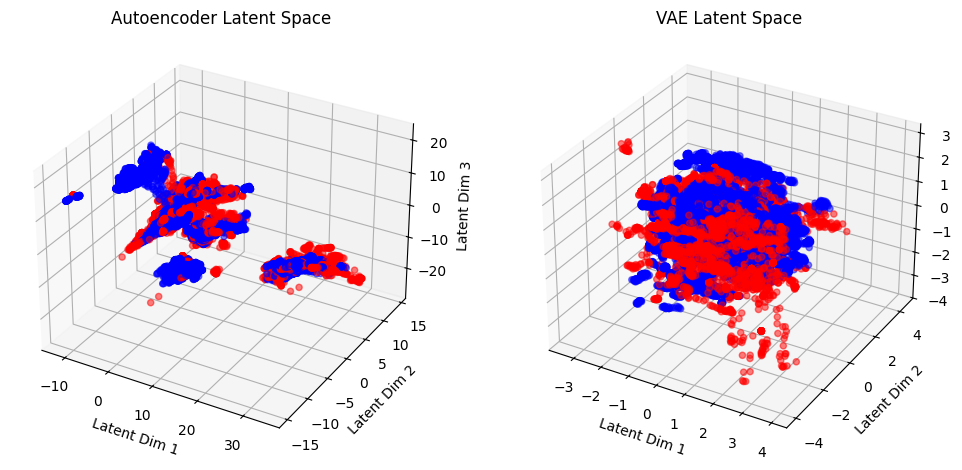

In [39]:
# make a 3d plort of the ae and vae latent spaces colored by mortality
fig = plt.figure(figsize=(12, 6))
ax1 = fig.add_subplot(121, projection='3d')
colors = ['red' if y == 1 else 'blue' for y in y_final_24]
ax1.scatter(z_ae[:,0], z_ae[:,1], z_ae[:,2], c=colors, alpha=0.5)
ax1.set_title('Autoencoder Latent Space')
ax1.set_xlabel('Latent Dim 1')
ax1.set_ylabel('Latent Dim 2')
ax1.set_zlabel('Latent Dim 3')

ax2 = fig.add_subplot(122, projection='3d')
ax2.scatter(z_vae[:,0], z_vae[:,1], z_vae[:,2], c=colors, alpha=0.5)
ax2.set_title('VAE Latent Space')
ax2.set_xlabel('Latent Dim 1')
ax2.set_ylabel('Latent Dim 2')
ax2.set_zlabel('Latent Dim 3')
plt.show()

In [ ]:
# Extract latent features (the "health scores")
with torch.no_grad():
    _, latent = model(X_tensor)
latent_np = latent.numpy()

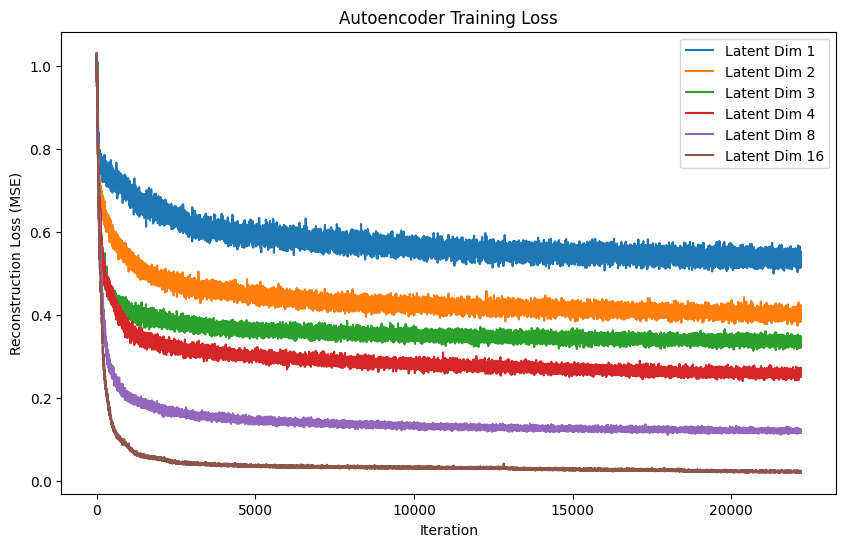

In [20]:
# plot losses for each latent dimension
plt.figure(figsize=(10, 6))
for latent_dim, loss_values in losses.items():
    plt.plot(loss_values, label=f'Latent Dim {latent_dim}')
plt.xlabel('Iteration')
plt.ylabel('Reconstruction Loss (MSE)')
plt.title('Autoencoder Training Loss')
plt.legend()
plt.show()

# VAE

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset




# Convert to torch tensors
X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
dataset = TensorDataset(X_tensor)
loader = DataLoader(dataset, batch_size=2048, shuffle=True)


# try different latent dimensions
latent_dims = [1, 2, 3, 4, 8, 16]

# create storage for losses which we will plot after
losses = {}

for latent_dim in latent_dims:
    losses[latent_dim] = []
    print(f"\nTraining VAE with latent dimension: {latent_dim}")

    # Example usage
    input_dim = X_scaled.shape[1]
    vae = VAE(input_dim, latent_dim)
    optimizer = optim.Adam(vae.parameters(), lr=1e-3)

    X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
    n_epochs = 25
    for epoch in range(n_epochs):
        print(f"Epoch {epoch+1}/{n_epochs}")
        batch_num = 0
        for batch in loader:
            batch_num += 1
            if batch_num % 100 == 0:
                print(f"  Batch {batch_num}")
            x_batch = batch[0]
            optimizer.zero_grad()
            x_hat, mu, logvar = vae(x_batch)
            loss = vae_loss(x_hat, x_batch, mu, logvar)
            losses[latent_dim].append(loss.item())
            loss.backward()
            optimizer.step()
        if (epoch+1) % 1 == 0:
            print(f"Epoch {epoch+1}/{n_epochs}, Loss={loss.item():.4f}")



Training VAE with latent dimension: 1
Epoch 1/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 1/25, Loss=48220.6328
Epoch 2/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 2/25, Loss=47959.6523
Epoch 3/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 3/25, Loss=45477.2891
Epoch 4/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 4/25, Loss=45771.4375
Epoch 5/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 5/25, Loss=45095.8086
Epoch 6/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 6/25, Loss=45343.7383
Epoch 7/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 7/25, Loss=43562.0469
Epoch 8/25
  Bat

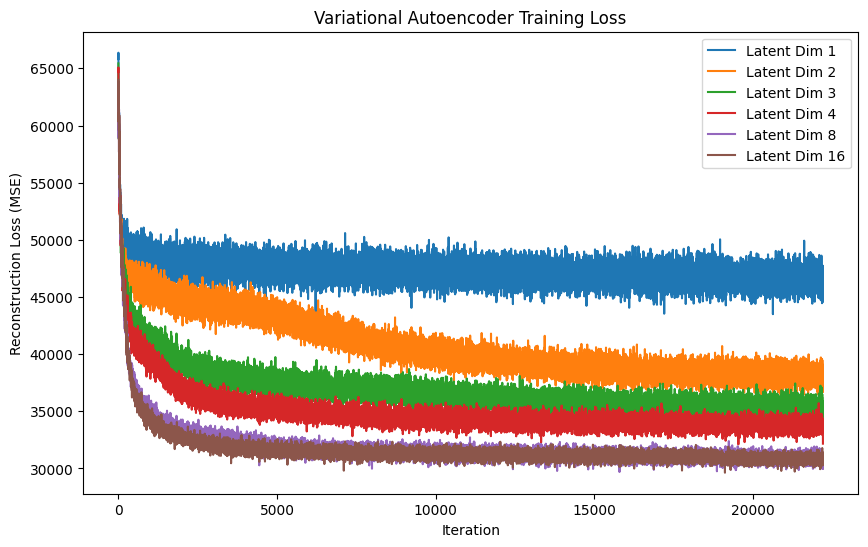

In [29]:
# plot losses for each latent dimension
plt.figure(figsize=(10, 6))
for latent_dim, loss_values in losses.items():
    plt.plot(loss_values, label=f'Latent Dim {latent_dim}')
plt.xlabel('Iteration')
plt.ylabel('Reconstruction Loss (MSE)')
plt.title('Variational Autoencoder Training Loss')
plt.legend()
plt.show()

In [31]:
# try different latent dimensions
latent_dims = [1, 2, 3, 4, 8, 16]

# create storage for losses which we will plot after
losses = {}

for latent_dim in latent_dims:
    losses[latent_dim] = []
    print(f"\nTraining VAE with latent dimension: {latent_dim}")

    # Example usage
    input_dim = X_scaled.shape[1]
    vae = VAE(input_dim, latent_dim)
    optimizer = optim.Adam(vae.parameters(), lr=1e-2)

    X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
    n_epochs = 25
    for epoch in range(n_epochs):
        print(f"Epoch {epoch+1}/{n_epochs}")
        batch_num = 0
        for batch in loader:
            batch_num += 1
            if batch_num % 100 == 0:
                print(f"  Batch {batch_num}")
            x_batch = batch[0]
            optimizer.zero_grad()
            x_hat, mu, logvar = vae(x_batch)
            loss = vae_loss(x_hat, x_batch, mu, logvar)
            losses[latent_dim].append(loss.item())
            loss.backward()
            optimizer.step()
        if (epoch+1) % 1 == 0:
            print(f"Epoch {epoch+1}/{n_epochs}, Loss={loss.item():.4f}")


Training VAE with latent dimension: 1
Epoch 1/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 1/25, Loss=45784.8633
Epoch 2/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 2/25, Loss=45180.7109
Epoch 3/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 3/25, Loss=45449.9180
Epoch 4/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 4/25, Loss=44786.7969
Epoch 5/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 5/25, Loss=45555.6602
Epoch 6/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 6/25, Loss=45589.3750
Epoch 7/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 7/25, Loss=44526.5469
Epoch 8/25
  Bat

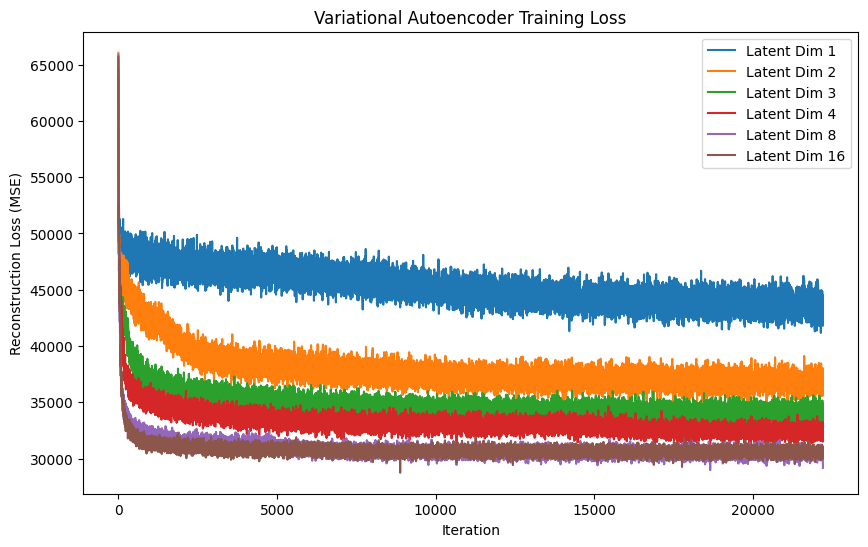

In [32]:
# plot losses for each latent dimension
plt.figure(figsize=(10, 6))
for latent_dim, loss_values in losses.items():
    plt.plot(loss_values, label=f'Latent Dim {latent_dim}')
plt.xlabel('Iteration')
plt.ylabel('Reconstruction Loss (MSE)')
plt.title('Variational Autoencoder Training Loss')
plt.legend()
plt.show()